Compare panel composition and organizer configurations.


In [1]:
import os, sys, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

def _build_data_tools():
    import json
    import os
    import re
    import unicodedata
    import warnings
    import numpy as np
    import pandas as pd
    from scipy import stats
    warnings.filterwarnings('ignore')

    def path_join(*parts):
        return os.path.normpath(os.path.join(*parts))

    def normalize_newlines(frame):
        for column in frame.select_dtypes(include=['object', 'string']).columns:
            frame[column] = frame[column].map(lambda value: value.replace('\r\n', '\n').replace('\r', '\n') if isinstance(value, str) else value)
        return frame
    from pathlib import Path
    _start = Path.cwd().resolve()
    _repo = next((p for p in (_start, *_start.parents) if (p / 'experiments/clinical_protocols').is_dir() and (p / 'data').is_dir()), None)
    if _repo is None:
        raise FileNotFoundError('Run the notebook from inside the repository.')
    if os.name == 'nt' and (not str(_repo).startswith(chr(92) * 2 + '?' + chr(92))):
        _repo = Path(chr(92) * 2 + '?' + chr(92) + str(_repo))
    GOLD = str(_repo)
    PAPER = str(_repo / 'results/clinical_evaluation')
    HERE = str(_repo / 'analyses/clinical_evaluation')
    ALPHA = GOLD
    RESEARCH = GOLD
    TABLES = path_join(PAPER, 'tables')
    FIGURES = path_join(PAPER, 'figures')
    os.makedirs(TABLES, exist_ok=True)
    os.makedirs(FIGURES, exist_ok=True)
    DATASET = str(_repo / 'data' / 'limfmed_dataset_gold.csv')
    PBASE = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_complete'
    PBASE_NON = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_truncated'
    ORG_DS = 'experiments/clinical_protocols/delphi_panels/heterogeneous_deepseek_organizer_complete'
    ORG_QWEN = 'experiments/clinical_protocols/delphi_panels/heterogeneous_qwen_organizer_complete'
    ORG_GEM = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gemini_external_organizer'
    PWEAK = 'experiments/clinical_protocols/delphi_panels/panel_qwen_organizer_gemini_deepseek_pro'
    PMIXED = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_gemini_glm'
    PSTRONG = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_glm_gpt120'
    HOMOG = {'gpt': 'experiments/homogeneous_panels/three_gpt_members', 'qwen': 'experiments/homogeneous_panels/three_qwen_members', 'deepseekv4': 'experiments/homogeneous_panels/three_deepseekv4_members_complete', 'gemini': 'experiments/homogeneous_panels/three_gemini_members'}
    FIX_PBASE = 'experiments/fixed_length_controls/delphi_panels/internal_panel_variants/standard_protocol/heterogeneous_gpt120_organizer'
    SINGLES = ['gpt', 'qwen', 'deepseekv4', 'deepseekv4pro', 'gemini', 'glm', 'kimi']
    MODEL_NAME = {'gpt': 'gpt-oss-120b', 'qwen': 'qwen3-235b-a22b', 'deepseekv4': 'deepseek-v4-flash', 'deepseekv4pro': 'deepseek-v4-pro', 'gemini': 'gemini-3.7-flash', 'glm': 'glm-5.2', 'kimi': 'kimi'}
    PANELS = {'P-base': (PBASE, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gpt', True), 'P-base/org-ds': (ORG_DS, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'deepseekv4', True), 'P-base/org-qwen': (ORG_QWEN, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'qwen', True), 'P-base/org-gemini': (ORG_GEM, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gemini', False), 'P-weak': (PWEAK, 'delphi_pweak_{d}_judge.csv', ['qwen', 'gemini', 'deepseekv4pro'], 'qwen', True), 'P-mixed': (PMIXED, 'delphi_pmixed_{d}_judge.csv', ['deepseekv4', 'gemini', 'glm'], 'deepseekv4', True), 'P-strong': (PSTRONG, 'delphi_pstrong_{d}_judge.csv', ['deepseekv4', 'glm', 'gpt'], 'deepseekv4', True), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_{d}_judge.csv', ['gpt'] * 3, 'gpt', True), 'homog qwen': (HOMOG['qwen'], 'delphi_homog_qwen_{d}_judge.csv', ['qwen'] * 3, 'qwen', True), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_{d}_judge.csv', ['deepseekv4'] * 3, 'deepseekv4', True), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_{d}_judge.csv', ['gemini'] * 3, 'gemini', True)}
    HETERO = ['P-base', 'P-weak', 'P-mixed', 'P-strong']
    HOMOGS = ['homog gpt', 'homog qwen', 'homog deepseekv4', 'homog gemini']
    ORGANIZER_ARMS = ['P-base', 'P-base/org-ds', 'P-base/org-qwen', 'P-base/org-gemini']
    RAW_RUN = {'P-base': PBASE + '/delphi_noroles.csv', 'P-base/org-ds': ORG_DS + '/delphi_noroles.csv', 'P-base/org-qwen': ORG_QWEN + '/delphi_noroles.csv', 'P-base/org-gemini': ORG_GEM + '/delphi_noroles.csv', 'P-weak': PWEAK + '/delphi_pweak_noroles.csv', 'P-mixed': PMIXED + '/delphi_pmixed_noroles.csv', 'P-strong': PSTRONG + '/delphi_pstrong_noroles.csv', 'homog gpt': HOMOG['gpt'] + '/delphi_homog_gpt_noroles.csv', 'homog qwen': HOMOG['qwen'] + '/delphi_homog_qwen_noroles.csv', 'homog deepseekv4': HOMOG['deepseekv4'] + '/delphi_homog_deepseekv4_noroles.csv', 'homog gemini': HOMOG['gemini'] + '/delphi_homog_gemini_noroles.csv'}
    ROUNDS_EVAL = {'P-base': (PBASE, 'delphi_base_noroles_protocol_r{r}_judge.csv'), 'P-weak': (PWEAK, 'delphi_pweak_noroles_protocol_r{r}_judge.csv'), 'P-mixed': (PMIXED, 'delphi_pmixed_noroles_protocol_r{r}_judge.csv'), 'P-strong': (PSTRONG, 'delphi_pstrong_noroles_protocol_r{r}_judge.csv'), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_noroles_protocol_r{r}_judge.csv'), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_noroles_protocol_r{r}_judge.csv'), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_noroles_protocol_r{r}_judge.csv')}

    def baseline_path(model, design='noroles', variant='nofix'):
        return f"experiments/{('clinical_protocols' if variant == 'nofix' else 'fixed_length_controls')}/single_model_baselines/baseline_{model}/llm_as_judge/baseline_{design}_{model}_judge.csv"

    def panel_path(name, design='noroles'):
        d, f, *_ = PANELS[name]
        return d + '/llm_as_judge/' + f.format(d=design)

    def _abs(rel):
        return rel if os.path.isabs(rel) else path_join(GOLD, rel)

    def read_csv(rel, filter_result=True):
        p = _abs(rel)
        if not os.path.exists(p):
            return None
        d = normalize_newlines(pd.read_csv(p, sep=';', encoding='utf-8-sig', low_memory=False))
        d.columns = [c.lstrip('\ufeff') for c in d.columns]
        if filter_result and 'table_source' in d.columns:
            d = d[d['table_source'].fillna('result_df') == 'result_df']
        return d

    def read_judge(rel):
        d = read_csv(rel)
        if d is None or 'Judge_score' not in d.columns:
            return None
        d = d.dropna(subset=['Judge_score', 'Vignette']).drop_duplicates('Vignette', keep='first')
        d['Judge_score'] = pd.to_numeric(d['Judge_score'], errors='coerce')
        return d.set_index('Vignette')

    def load_main_arms(design='noroles', include_usc=False):
        arms = {}
        for m in SINGLES:
            d = read_judge(baseline_path(m, design))
            if d is not None:
                arms[m] = d
        for name in PANELS:
            d = read_judge(panel_path(name, design))
            if d is not None:
                arms[name] = d
        if include_usc and design == 'noroles':
            for k in (3, 5, 7):
                d = read_judge(f'experiments/token_budget_controls/universal_self_consistency_gpt_seven_samples/llm_as_judge/usc_gpt_sc{k}_judge.csv')
                if d is not None:
                    arms[f'USC@{k} gpt'] = d
        return arms

    def score(arms, name):
        return arms[name]['Judge_score'].astype(float)

    def dataset():
        d = normalize_newlines(pd.read_csv(DATASET, sep=None, engine='python'))
        return d

    def protocol_text(d):
        for c in ('winner_protocol', 'baseline_protocol_anonymous', 'baseline_protocol'):
            if c in d.columns:
                return d[c].astype(str)
        raise KeyError('no protocol column')

    def strip_author(text):
        if not isinstance(text, str):
            return ''
        return re.split('(?im)^\\s*Protocol Author\\s*:', text, maxsplit=1)[0].rstrip()

    def n_words(text):
        return len(re.findall('\\S+', strip_author(text))) if isinstance(text, str) else np.nan

    def items(d):
        rows = []
        for v, s in d['judge_details'].dropna().items():
            try:
                arr = json.loads(s)
            except Exception:
                continue
            for it in arr:
                ax = next((t.split(':', 1)[1] for t in it.get('tags') or [] if isinstance(t, str) and t.startswith('axis:')), None)
                rows.append((v, int(it['id']), int(it.get('points', 0) or 0), ax, bool(it.get('met'))))
        return pd.DataFrame(rows, columns=['Vignette', 'cid', 'points', 'axis', 'met'])

    def item_matrix(arms, names, positive_only=True):
        frames = []
        for n in names:
            it = items(arms[n]).set_index(['Vignette', 'cid'])
            frames.append(it['met'].astype(int).rename(n))
            meta = it[['points', 'axis']]
        m = pd.concat(frames, axis=1, join='inner')
        m = m.join(meta, how='left')
        if positive_only:
            m = m[m['points'] > 0]
        return m
    ORD = {'SELF': 0, 'NONEMERG': 1, 'EMERG': 2}
    GT = {'Self-care appropriate': 'SELF', 'Requires non-emergent care': 'NONEMERG', 'Requires emergent care': 'EMERG'}
    _DASH = dict.fromkeys(map(ord, '‐‑‒–—―−\xad'), '-')

    def norm_label(x):
        if not isinstance(x, str) or not x.strip():
            return None
        x = x.strip()
        if x in GT:
            return GT[x]
        s = unicodedata.normalize('NFKC', x).translate(_DASH).lower()
        s = re.sub('\\s+', ' ', re.sub('[^a-z\\- ]', ' ', s)).strip()
        for k, v in (('requires emergent care', 'EMERG'), ('requires non-emergent care', 'NONEMERG'), ('self-care appropriate', 'SELF')):
            if k in s:
                return v
        if 'non-emergent' in s or 'non emergent' in s:
            return 'NONEMERG'
        if 'emergent' in s or 'emergency' in s:
            return 'EMERG'
        if 'self' in s:
            return 'SELF'
        return None
    _PAT = re.compile('emergency\\s*type\\s*[:\\-]\\s*[\\*_`#\\s]*([^\\n\\r\\*_|]{0,90})', re.I)

    def parse_triage(text):
        if not isinstance(text, str) or not text.strip():
            return None
        m = _PAT.search(unicodedata.normalize('NFKC', text).translate(_DASH))
        return norm_label(m.group(1)) if m else None

    def predicted_triage(d):
        if 'delphi_consensus_emergency_type' in d.columns:
            s = d['delphi_consensus_emergency_type'].map(norm_label)
            if s.notna().mean() > 0.5:
                return s
        return protocol_text(d).map(parse_triage)

    def true_triage(d):
        return d['Type'].map(GT)

    def participants(d):
        return sorted((c.split('__', 1)[1] for c in d.columns if c.startswith('r1_emergency__')))

    def paired(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(float), b.loc[ix].astype(float))
        dd = x - y
        p = stats.wilcoxon(x, y).pvalue if (dd != 0).any() else np.nan
        return {'n': len(ix), 'delta': float(dd.mean()), 'share_gt': float((dd > 0).mean()), 'p_wilcoxon': float(p)}

    def boot_ci(x, B=10000, seed=20260922, alpha=0.05, stat=np.mean):
        rng = np.random.default_rng(seed)
        x = np.asarray(x, float)
        n = len(x)
        idx = rng.integers(0, n, (B, n))
        s = stat(x[idx], axis=1)
        return (float(np.quantile(s, alpha / 2)), float(np.quantile(s, 1 - alpha / 2)))

    def boot_ci_two_level(x, cluster, B=10000, seed=20260922, alpha=0.05):
        rng = np.random.default_rng(seed)
        df = pd.DataFrame({'x': np.asarray(x, float), 'c': np.asarray(cluster)})
        groups = [g['x'].to_numpy() for _, g in df.groupby('c')]
        G = len(groups)
        out = np.empty(B)
        for b in range(B):
            pick = rng.integers(0, G, G)
            vals = []
            for i in pick:
                g = groups[i]
                vals.append(g[rng.integers(0, len(g), len(g))])
            out[b] = np.concatenate(vals).mean()
        return (float(np.quantile(out, alpha / 2)), float(np.quantile(out, 1 - alpha / 2)))

    def holm(p):
        p = np.asarray(p, float)
        m = len(p)
        order = np.argsort(p)
        adj = np.empty(m)
        run = 0.0
        for i, k in enumerate(order):
            run = max(run, (m - i) * p[k])
            adj[k] = min(run, 1.0)
        return adj

    def mcnemar_exact(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(bool), b.loc[ix].astype(bool))
        n10, n01 = (int((x & ~y).sum()), int((~x & y).sum()))
        p = stats.binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
        return {'n': len(ix), 'acc_a': float(x.mean()), 'acc_b': float(y.mean()), 'n10': n10, 'n01': n01, 'p': float(p)}

    def wilson(k, n, z=1.96):
        p = k / n
        d = 1 + z ** 2 / n
        c = (p + z ** 2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
        return (c - h, c + h)

    def tost_paired(dvec, margin):
        d = np.asarray(dvec, float)
        n = len(d)
        m, se = (d.mean(), d.std(ddof=1) / np.sqrt(n))
        p_low = stats.t.sf((m + margin) / se, n - 1)
        p_up = stats.t.cdf((m - margin) / se, n - 1)
        return float(max(p_low, p_up))

    def fmt_p(p):
        if p is None or not np.isfinite(p):
            return 'n/a'
        if p < 0.0001:
            return f'{p:.1e}'
        return f'{p:.3f}' if p >= 0.001 else f'{p:.4f}'

    def save_table(df, name, index=True):
        path = path_join(TABLES, name)
        df.to_csv(path, sep=';', encoding='utf-8-sig', index=index)
        print(f'saved tables/{name} ({len(df)} rows)')
        return path
    return locals()
from types import SimpleNamespace
P = SimpleNamespace(**_build_data_tools())
del _build_data_tools
pd.set_option('display.width', 220)
arms = P.load_main_arms()


In [2]:
rows = []
for h, m in [('homog gpt', 'gpt'), ('homog qwen', 'qwen'), ('homog deepseekv4', 'deepseekv4'), ('homog gemini', 'gemini')]:
    r = P.paired(P.score(arms, h), P.score(arms, m))
    rows.append({'contrast': f'{h} − {P.MODEL_NAME[m]}', **r})
for h in ['homog gpt', 'homog qwen', 'homog deepseekv4', 'homog gemini']:
    r = P.paired(P.score(arms, 'P-base'), P.score(arms, h))
    rows.append({'contrast': f'P-base − {h}', **r})
    ix = P.score(arms, 'P-base').index.intersection(P.score(arms, h).index)
    d = (P.score(arms, 'P-base').loc[ix] - P.score(arms, h).loc[ix]).values
    rows[-1]['TOST_0.027'] = P.tost_paired(d, 0.027)
hom = pd.DataFrame(rows)
hom['p_holm'] = P.holm(hom.p_wilcoxon)
display(hom.round(4))
P.save_table(hom, 'homogeneous_panel_comparisons.csv', index=False)


,contrast,n,delta,share_gt,p_wilcoxon,TOST_0.027,p_holm
0,homog gpt − gpt-oss-120b,229,0.1330,0.7904,0.0000,NaN,0.0000
1,homog qwen − qwen3-235b-a22b,229,0.1357,0.8341,0.0000,NaN,0.0000
2,homog deepseekv4 − deepseek-v4-flash,228,0.1405,0.7807,0.0000,NaN,0.0000
3,homog gemini − gemini-3.7-flash,229,0.2925,0.9607,0.0000,NaN,0.0000
4,P-base − homog gpt,229,0.0312,0.4716,0.0016,0.6700,0.0032
5,P-base − homog qwen,229,0.0921,0.7074,0.0000,1.0000,0.0000
6,P-base − homog deepseekv4,229,0.0089,0.4847,0.1634,0.0154,0.1634
7,P-base − homog gemini,229,0.0727,0.6376,0.0000,1.0000,0.0000


saved tables/homogeneous_panel_comparisons.csv (8 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\homogeneous_panel_comparisons.csv'

In [3]:
org = ['P-base', 'P-base/org-ds', 'P-base/org-qwen', 'P-base/org-gemini']
lab = {'P-base': 'gpt-oss-120b (in panel)', 'P-base/org-ds': 'deepseek-v4-flash (in panel)', 'P-base/org-qwen': 'qwen3-235b (in panel)', 'P-base/org-gemini': 'gemini-3.7-flash (outside, no vote)'}
solo = {'P-base': 'gpt', 'P-base/org-ds': 'deepseekv4', 'P-base/org-qwen': 'qwen', 'P-base/org-gemini': 'gemini'}
rows = []
for o in org:
    s = P.score(arms, o)
    rows.append({'organizer': lab[o], 'panel_score': s.mean(), 'organizer_alone': P.score(arms, solo[o]).mean(), 'median_words': P.protocol_text(arms[o]).map(P.n_words).median(), 'triage_acc': (P.predicted_triage(arms[o]) == P.true_triage(arms[o])).mean()})
orgt = pd.DataFrame(rows)
display(orgt.round(4))
pairs = []
for i in range(len(org)):
    for j in range(i + 1, len(org)):
        r = P.paired(P.score(arms, org[i]), P.score(arms, org[j]))
        pairs.append({'a': lab[org[i]], 'b': lab[org[j]], **r})
pairs = pd.DataFrame(pairs)
pairs['p_holm'] = P.holm(pairs.p_wilcoxon)
display(pairs.round(4))
print('Spearman(organizer solo strength, panel score):', stats.spearmanr(orgt.organizer_alone, orgt.panel_score))
P.save_table(orgt, 'organizer_configuration_scores.csv', index=False)
P.save_table(pairs, 'paired_organizer_comparisons.csv', index=False)


,organizer,panel_score,organizer_alone,median_words,triage_acc
0,gpt-oss-120b (in panel),0.7899,0.6258,469.0,0.7860
1,deepseek-v4-flash (in panel),0.8111,0.6401,605.0,0.8253
2,qwen3-235b (in panel),0.7592,0.5622,464.0,0.8297
3,"gemini-3.7-flash (outside, no vote)",0.7995,0.4247,503.0,0.8166


,a,b,n,delta,share_gt,p_wilcoxon,p_holm
0,gpt-oss-120b (in panel),deepseek-v4-flash (in panel),229,-0.0211,0.3450,0.0133,0.0398
1,gpt-oss-120b (in panel),qwen3-235b (in panel),229,0.0308,0.4978,0.0001,0.0005
2,gpt-oss-120b (in panel),"gemini-3.7-flash (outside, no vote)",229,-0.0096,0.3624,0.1402,0.2804
3,deepseek-v4-flash (in panel),qwen3-235b (in panel),229,0.0519,0.5895,0.0000,0.0000
4,deepseek-v4-flash (in panel),"gemini-3.7-flash (outside, no vote)",229,0.0115,0.4454,0.2045,0.2804
5,qwen3-235b (in panel),"gemini-3.7-flash (outside, no vote)",229,-0.0403,0.2664,0.0000,0.0000


Spearman(organizer solo strength, panel score): SignificanceResult(statistic=np.float64(0.39999999999999997), pvalue=np.float64(0.6))
saved tables/organizer_configuration_scores.csv (4 rows)
saved tables/paired_organizer_comparisons.csv (6 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\paired_organizer_comparisons.csv'

In [4]:
rows = []
for o in org:
    d = arms[o]
    rows.append(pd.DataFrame({'case': d.index, 'y': d.Judge_score.values, 'org': o, 'lw': np.log(P.protocol_text(d).map(P.n_words).astype(float).values)}))
L = pd.concat(rows, ignore_index=True)
m0 = smf.ols("y ~ C(org, Treatment('P-base/org-ds')) + C(case)", L).fit()
m1 = smf.ols("y ~ C(org, Treatment('P-base/org-ds')) + lw + C(case)", L).fit()
keep = [k for k in m0.params.index if k.startswith('C(org')]
print(pd.DataFrame({'coef_no_length': m0.params[keep], 'p0': m0.pvalues[keep], 'coef_with_log_length': m1.params[keep], 'p1': m1.pvalues[keep]}).round(4))
print('log(words) coef:', round(m1.params['lw'], 4), 'p', f"{m1.pvalues['lw']:.1e}")


                                                    coef_no_length      p0  coef_with_log_length      p1
C(org, Treatment('P-base/org-ds'))[T.P-base]               -0.0211  0.0104                0.0130  0.2015
C(org, Treatment('P-base/org-ds'))[T.P-base/org...         -0.0115  0.1609                0.0087  0.3275
C(org, Treatment('P-base/org-ds'))[T.P-base/org...         -0.0519  0.0000               -0.0154  0.1380
log(words) coef: 0.1423 p 4.7e-08


In [5]:
IM = P.item_matrix(arms, org + ['gpt', 'qwen', 'deepseekv4'])
rows = []
for o in org:
    rows.append({'organizer': lab[o], **{f'agree_{P.MODEL_NAME[m]}': (IM[o] == IM[m]).mean() for m in ['gpt', 'qwen', 'deepseekv4']}})
display(pd.DataFrame(rows).round(4))


,organizer,agree_gpt-oss-120b,agree_qwen3-235b-a22b,agree_deepseek-v4-flash
0,gpt-oss-120b (in panel),0.7442,0.7078,0.7575
1,deepseek-v4-flash (in panel),0.7271,0.6958,0.7506
2,qwen3-235b (in panel),0.7494,0.7404,0.7678
3,"gemini-3.7-flash (outside, no vote)",0.7425,0.7147,0.7558


In [6]:
IM7 = P.item_matrix(arms, P.SINGLES)
X = IM7[P.SINGLES].astype(float)
R = X.corr()
R.index = R.columns = [P.MODEL_NAME[m] for m in P.SINGLES]
display(R.round(3))

def keff(members):
    names = [P.MODEL_NAME[m] for m in members]
    rho = np.mean([R.loc[a, b] for i, a in enumerate(names) for b in names[i + 1:]])
    k = len(members)
    return (rho, k / (1 + (k - 1) * rho), 1 / rho)
rows = []
for pn in ['P-base', 'P-weak', 'P-mixed', 'P-strong']:
    rho, ke, lim = keff(P.PANELS[pn][2])
    rows.append({'panel': pn, 'mean_error_corr': rho, 'k_eff_of_3': ke, 'limit_k_inf': lim})
kt = pd.DataFrame(rows)
display(kt.round(3))
P.save_table(kt, 'effective_independent_panel_votes.csv', index=False)


,gpt-oss-120b,qwen3-235b-a22b,deepseek-v4-flash,deepseek-v4-pro,gemini-3.7-flash,glm-5.2,kimi
gpt-oss-120b,1.000,0.575,0.570,0.563,0.532,0.595,0.569
qwen3-235b-a22b,0.575,1.000,0.600,0.639,0.593,0.629,0.595
deepseek-v4-flash,0.570,0.600,1.000,0.621,0.573,0.617,0.593
deepseek-v4-pro,0.563,0.639,0.621,1.000,0.615,0.638,0.586
gemini-3.7-flash,0.532,0.593,0.573,0.615,1.000,0.612,0.589
glm-5.2,0.595,0.629,0.617,0.638,0.612,1.000,0.596
kimi,0.569,0.595,0.593,0.586,0.589,0.596,1.000


,panel,mean_error_corr,k_eff_of_3,limit_k_inf
0,P-base,0.581,1.387,1.720
1,P-weak,0.616,1.344,1.624
2,P-mixed,0.601,1.363,1.665
3,P-strong,0.594,1.371,1.684


saved tables/effective_independent_panel_votes.csv (4 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\effective_independent_panel_votes.csv'

In [7]:
rows = []
for pn in ['P-base', 'P-weak', 'P-mixed', 'P-strong', 'homog gpt', 'homog qwen', 'homog deepseekv4', 'homog gemini']:
    mem = P.PANELS[pn][2]
    Mm = pd.concat([P.score(arms, m).rename(f'm{i}') for i, m in enumerate(mem)], axis=1).dropna()
    rows.append({'panel': pn, 'mean_member': Mm.mean(axis=1).mean(), 'min_member': Mm.mean().min(), 'max_member': Mm.mean().max(), 'panel_score': P.score(arms, pn).mean(), 'hetero': int(pn in P.HETERO)})
comp = pd.DataFrame(rows)
display(comp.round(4))
fit = smf.ols('panel_score ~ mean_member + hetero', comp).fit()
print(fit.params.round(3), '\n R2 =', round(fit.rsquared, 3))
print('spread of member means:', round(comp.mean_member.max() - comp.mean_member.min(), 3), '| spread of panel scores:', round(comp.panel_score.max() - comp.panel_score.min(), 3))
P.save_table(comp, 'panel_synthesis_compression.csv', index=False)


,panel,mean_member,min_member,max_member,panel_score,hetero
0,P-base,0.6088,0.5611,0.6401,0.7899,1
1,P-weak,0.5157,0.4247,0.5622,0.7453,1
2,P-mixed,0.5498,0.4234,0.6401,0.7864,1
3,P-strong,0.6170,0.5858,0.6401,0.8061,1
4,homog gpt,0.6258,0.6258,0.6258,0.7588,0
5,homog qwen,0.5622,0.5622,0.5622,0.6979,0
6,homog deepseekv4,0.6401,0.6401,0.6401,0.7811,0
7,homog gemini,0.4247,0.4247,0.4247,0.7172,0


Intercept      0.569
mean_member    0.302
hetero         0.040
dtype: float64 
 R2 = 0.696
spread of member means: 0.215 | spread of panel scores: 0.108
saved tables/panel_synthesis_compression.csv (8 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\panel_synthesis_compression.csv'

In [8]:
import glob
base = P.read_judge('experiments/panel_parameter_sweeps/rounds/llm_as_judge/delphi_optimum_early_stop_judge.csv')
rows = [{'group': 'k=3 (reference)', 'k': 3, 'score': base.Judge_score.mean(), 'n': len(base)}]
for f in sorted(glob.glob(P.path_join(P.GOLD, 'experiments/panel_parameter_sweeps/experts/llm_as_judge/*_judge.csv'))):
    d = P.read_judge(f)
    k = int(re.search('_(\\d+)models', f).group(1))
    r = P.paired(d.Judge_score, base.Judge_score)
    ix = d.index.intersection(base.index)
    rows.append({'group': os.path.basename(f).replace('delphi_experts_', '').replace('_judge.csv', ''), 'k': k, 'score': d.Judge_score.mean(), 'n': len(d), 'delta_vs_k3': r['delta'], 'p': r['p_wilcoxon'], 'TOST_0.05': P.tost_paired((d.Judge_score.loc[ix] - base.Judge_score.loc[ix]).values, 0.05)})
size = pd.DataFrame(rows).sort_values('k')
display(size.round(4))
P.save_table(size, 'panel_size_and_quality.csv', index=False)


,group,k,score,n,delta_vs_k3,p,TOST_0.05
0,k=3 (reference),3,0.8194,60,NaN,NaN,NaN
2,group2_4models,4,0.8071,60,-0.0123,0.4909,0.0120
3,group3_5models,5,0.8276,60,0.0082,0.3498,0.0026
4,group4_5models,5,0.8169,60,-0.0025,0.9415,0.0007
6,group6_5models,5,0.6384,60,-0.1810,0.0000,1.0000
7,group7_6models,6,0.8249,60,0.0055,0.6152,0.0011
5,group5_7models,7,0.8390,60,0.0197,0.1733,0.0211
1,group1_10models,10,0.8198,60,0.0004,0.8734,0.0010


saved tables/panel_size_and_quality.csv (8 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\panel_size_and_quality.csv'

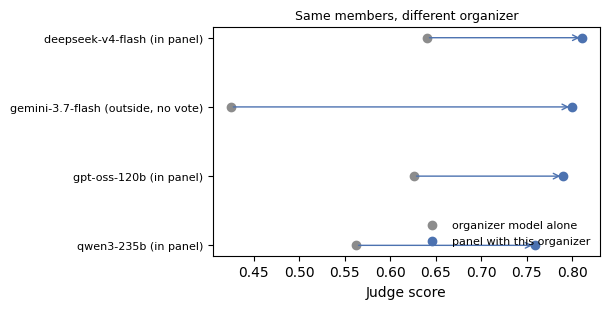

In [9]:
fig, ax = plt.subplots(figsize=(6.2, 3.2))
o = orgt.sort_values('panel_score')
y = np.arange(len(o))
ax.scatter(o.organizer_alone, y, color='#8C8C8C', label='organizer model alone', zorder=3)
ax.scatter(o.panel_score, y, color='#4C72B0', label='panel with this organizer', zorder=3)
for yi, (a, b) in enumerate(zip(o.organizer_alone, o.panel_score)):
    ax.annotate('', xy=(b, yi), xytext=(a, yi), arrowprops=dict(arrowstyle='->', color='#4C72B0', lw=1))
ax.set_yticks(y)
ax.set_yticklabels(o.organizer, fontsize=8)
ax.set_xlabel('Judge score')
ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.set_title('Same members, different organizer', fontsize=9)
fig.tight_layout()
fig.savefig(P.path_join(P.FIGURES, 'S_organizer_configuration_scores.png'), dpi=220)
